In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('superstore_orders.csv')
df.head(5)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


### Compute CLV for each customer

In [ ]:
clv = df.groupby('Customer ID').agg(
                            CLV=('Profit', 'sum'),
                            Orders=('Order ID', 'nunique'),
                            TotalSales=('Sales', 'sum')
                        ).reset_index()


clv['AvgProfitPerOrder'] = (clv['CLV'] / clv['Orders']).round(2)
clv.head()

,Customer ID,CLV,Orders,TotalSales,AvgProfitPerOrder
0,AA-10315,-362.8825,5,5563.560,-72.58
1,AA-10375,277.3824,9,1056.390,30.82
2,AA-10480,435.8274,4,1790.512,108.96
3,AA-10645,857.8033,6,5086.935,142.97
4,AB-10015,129.3465,3,886.156,43.12


### Look at spread of CLV

In [ ]:
clv['CLV'].describe()
print('Unprofitable customers:', (clv['CLV'] < 0).sum())

Unprofitable customers: 159


### Group customers into value tiers

In [ ]:
clv['Tier'] = pd.qcut(clv['CLV'], 4,
                      labels=['Low','Medium','High','Top'])


summary = clv.groupby('Tier', observed=True).agg(
                            Customers=('Customer ID', 'count'),
                            AvgCLV=('CLV', 'mean'),
                            TotalProfit=('CLV', 'sum')
                        ).round(1)

In [ ]:
summary         

,Customers,AvgCLV,TotalProfit
Tier,,,
Low,201,-352.1,-70775.0
Medium,201,133.5,26839.5
High,201,363.4,73038.1
Top,201,1309.4,263194.2


###  See each tier's share of total profit

In [ ]:
summary['%ofProfit'] = (summary['TotalProfit'] / clv['CLV'].sum() * 100).round(1)

summary

,Customers,AvgCLV,TotalProfit,%ofProfit
Tier,,,,
Low,201,-352.1,-70775.0,-24.2
Medium,201,133.5,26839.5,9.2
High,201,363.4,73038.1,25.0
Top,201,1309.4,263194.2,90.0


### Visualize and identify the best customers

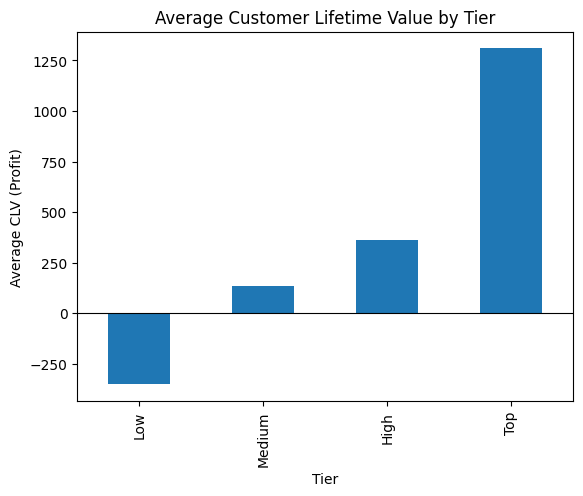

In [ ]:
clv.groupby('Tier', observed=True)['CLV'].mean().plot(kind='bar')
plt.axhline(0, color='black', linewidth=0.8)
plt.ylabel('Average CLV (Profit)')
plt.title('Average Customer Lifetime Value by Tier')
plt.show()

In [ ]:
# the ten most valuable customers
clv.nlargest(10, 'CLV')[['Customer ID', 'CLV', 'Orders']]

,Customer ID,CLV,Orders
752,TC-20980,8981.3239,5
632,RB-19360,6976.0959,6
680,SC-20095,5757.4119,9
328,HL-15040,5622.4292,6
6,AB-10105,5444.8055,10
741,TA-21385,4703.7883,4
161,CM-12385,3899.8904,4
433,KD-16495,3038.6254,12
48,AR-10540,2884.6208,6
235,DR-12940,2869.0760,8
